# FEM benchmark: periodic silver nanoparticle monolayer

This notebook solves one **3D periodic unit cell** of an infinite square lattice with the frequency-domain finite-element method (FEM). It follows `silver_monolayer.ipynb`:

- square period $a=470$ nm;
- one spherical silver particle per cell, centered at $z=0$;
- particle **radius** $r=50$ nm (the reference notebook sets `particle_radius = 50`);
- vacuum background, normal incidence along $+z$, and x polarization;
- silver permittivity from `silver_optical_data.csv`.

> If “50 nm nanoparticle” means diameter, set `PARTICLE_RADIUS_NM = 25.0`.

The side faces are periodic with zero Bloch phase. Upper and lower half-space perfectly matched layers (PMLs) absorb the scattered field before it reaches the truncated outer boundaries. Extinction is evaluated from absorption plus every propagating reflected and non-specular transmitted Floquet order. This remains valid when diffraction channels open below 470 nm.

Use an environment with `ngsolve`, `numpy`, `pandas`, and `matplotlib`. The notebook deliberately does not modify the active environment.

In [9]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

try:
    from netgen.occ import (
        Box, Glue, IdentificationType, OCCGeometry, Pnt, Sphere, X, Y, Z
    )
    from ngsolve import (
        BND, BilinearForm, CF, GridFunction, HCurl,
        InnerProduct, Integrate, LinearForm, Mesh, Periodic, TaskManager,
        curl, dx, exp, x, y, z
    )
except ImportError as exc:
    raise ImportError(
        "This benchmark requires NGSolve/Netgen. Install 'ngsolve' in the "
        "notebook environment, restart the kernel, and rerun all cells."
    ) from exc

## Configuration

Set `QUICK_RUN=False` for the full 350–700 nm spectrum. It uses 1 nm spacing from 440 to 500 nm around the Rayleigh feature and 5 nm spacing elsewhere.

In [10]:
# Coordinates are in nm and wavenumbers in nm^-1.
LATTICE_CONSTANT_NM = 470.0
PARTICLE_RADIUS_NM = 50.0
AIR_CLEARANCE_TO_MONITOR_NM = 400.0
AIR_BUFFER_TO_PML_NM = 100.0
MONITOR_Z_NM = PARTICLE_RADIUS_NM + AIR_CLEARANCE_TO_MONITOR_NM
PHYSICAL_HALF_HEIGHT_NM = MONITOR_Z_NM + AIR_BUFFER_TO_PML_NM
PML_THICKNESS_NM = 200.0
PML_ATTENUATION = 3.0
AIR_MAX_ELEMENT_NM = 45.0
PML_MAX_ELEMENT_NM = 40.0
PARTICLE_MAX_ELEMENT_NM = 14.0
CURVE_ORDER = 3
FEM_ORDER = 2
DIRECT_SOLVER = "umfpack"
POWER_BALANCE_WARNING = 0.02
QUICK_RUN = False

if QUICK_RUN:
    WAVELENGTHS_NM = np.array(
        [350, 400, 450, 470, 490, 550, 625, 700], dtype=float
    )
else:
    WAVELENGTHS_NM = np.concatenate((
        np.arange(350.0, 440.0, 5.0),
        np.arange(440.0, 501.0, 1.0),
        # np.arange(505.0, 701.0, 5.0),
    ))

assert 2 * PARTICLE_RADIUS_NM < LATTICE_CONSTANT_NM
assert PARTICLE_RADIUS_NM < PHYSICAL_HALF_HEIGHT_NM
assert PARTICLE_RADIUS_NM < MONITOR_Z_NM < PHYSICAL_HALF_HEIGHT_NM
assert PML_THICKNESS_NM > 0
TOTAL_HALF_HEIGHT_NM = PHYSICAL_HALF_HEIGHT_NM + PML_THICKNESS_NM

## Silver optical constants

The CSV wavelength in metres is converted explicitly to nm. Real and imaginary permittivity are interpolated separately; extrapolation is rejected.

In [11]:
def locate_monolayer_file(filename: str) -> Path:
    """Find an input file from common notebook launch locations."""
    candidates = (
        Path.cwd() / filename,
        Path.cwd() / "test" / "monolayers" / filename,
    )
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not find {filename!r}. Start Jupyter from the repository root "
        "or from test/monolayers."
    )


@dataclass(frozen=True)
class SilverPermittivity:
    """Tabulated silver permittivity with range-checked interpolation."""

    wavelength_nm: np.ndarray
    epsilon: np.ndarray

    @classmethod
    def from_csv(cls, path: Path) -> "SilverPermittivity":
        """Load wavelength and complex relative permittivity from CSV."""
        table = pd.read_csv(path)
        required = {"lambda_real", "e1", "e2"}
        missing = required.difference(table.columns)
        if missing:
            raise ValueError(f"Missing optical-data columns: {sorted(missing)}")
        wavelength_nm = table["lambda_real"].to_numpy(dtype=float) * 1e9
        epsilon = (
            table["e1"].to_numpy(dtype=float)
            + 1j * table["e2"].to_numpy(dtype=float)
        )
        order = np.argsort(wavelength_nm)
        return cls(wavelength_nm[order], epsilon[order])

    def at(self, wavelength_nm: float) -> complex:
        """Interpolate at one wavelength without extrapolation."""
        lower, upper = self.wavelength_nm[[0, -1]]
        if not lower <= wavelength_nm <= upper:
            raise ValueError(
                f"{wavelength_nm:g} nm is outside [{lower:g}, {upper:g}] nm."
            )
        real = np.interp(
            wavelength_nm, self.wavelength_nm, self.epsilon.real
        )
        imag = np.interp(
            wavelength_nm, self.wavelength_nm, self.epsilon.imag
        )
        return complex(real, imag)


silver = SilverPermittivity.from_csv(
    locate_monolayer_file("silver_optical_data.csv")
)
epsilon_samples = np.array([silver.at(value) for value in WAVELENGTHS_NM])
display(pd.DataFrame({
    "wavelength_nm": WAVELENGTHS_NM,
    "epsilon_real": epsilon_samples.real,
    "epsilon_imag": epsilon_samples.imag,
}).head())

,wavelength_nm,epsilon_real,epsilon_imag
0,350.0,-1.734350,0.331224
1,355.0,-2.049044,0.278132
2,360.0,-2.333350,0.244501
3,365.0,-2.592715,0.234817
4,370.0,-2.851768,0.226534


## Periodic conforming mesh with PML slabs

The physical region extends from $z=-550$ to $+550$ nm. Each monitor is 400 nm from the nearest particle surface, at $z=\pm450$ nm, followed by another 100 nm of ordinary air before the PML begins. Two 200 nm PML slabs extend the complete box to $z=\pm750$ nm, giving a 1500 nm total height. Thus each side contains 500 nm of physical air between the particle surface and its PML. Opposite x/y faces are periodic across every layer. The silver/air interface is conforming and the sphere is represented with curved elements.

In [12]:
def build_periodic_mesh() -> Mesh:
    """Build a conforming sphere-in-air periodic unit-cell mesh."""
    half_period = LATTICE_CONSTANT_NM / 2
    central_cell = Box(
        Pnt(-half_period, -half_period, -MONITOR_Z_NM),
        Pnt(half_period, half_period, MONITOR_Z_NM),
    )
    central_cell.faces.Min(Z).name = "monitor_bottom"
    central_cell.faces.Max(Z).name = "monitor_top"

    top_air = Box(
        Pnt(-half_period, -half_period, MONITOR_Z_NM),
        Pnt(half_period, half_period, PHYSICAL_HALF_HEIGHT_NM),
    )
    top_air.mat("air")
    bottom_air = Box(
        Pnt(-half_period, -half_period, -PHYSICAL_HALF_HEIGHT_NM),
        Pnt(half_period, half_period, -MONITOR_Z_NM),
    )
    bottom_air.mat("air")

    top_pml = Box(
        Pnt(-half_period, -half_period, PHYSICAL_HALF_HEIGHT_NM),
        Pnt(half_period, half_period, TOTAL_HALF_HEIGHT_NM),
    )
    top_pml.mat("pml_top")
    top_pml.maxh = PML_MAX_ELEMENT_NM
    top_pml.faces.Max(Z).name = "pml_outer_top"

    bottom_pml = Box(
        Pnt(-half_period, -half_period, -TOTAL_HALF_HEIGHT_NM),
        Pnt(half_period, half_period, -PHYSICAL_HALF_HEIGHT_NM),
    )
    bottom_pml.mat("pml_bottom")
    bottom_pml.maxh = PML_MAX_ELEMENT_NM
    bottom_pml.faces.Min(Z).name = "pml_outer_bottom"

    particle = Sphere(Pnt(0, 0, 0), PARTICLE_RADIUS_NM)
    particle.mat("silver")
    particle.maxh = PARTICLE_MAX_ELEMENT_NM
    central_air = central_cell - particle
    central_air.mat("air")

    shape = Glue([
        bottom_pml, bottom_air, central_air, particle, top_air, top_pml
    ])
    shape.faces.Min(X).name = "periodic_x_min"
    shape.faces.Max(X).name = "periodic_x_max"
    shape.faces.Min(Y).name = "periodic_y_min"
    shape.faces.Max(Y).name = "periodic_y_max"
    shape.faces.Min(X).Identify(
        shape.faces.Max(X), "periodic_x", IdentificationType.PERIODIC
    )
    shape.faces.Min(Y).Identify(
        shape.faces.Max(Y), "periodic_y", IdentificationType.PERIODIC
    )

    geometry = OCCGeometry(shape)
    ngmesh = geometry.GenerateMesh(maxh=AIR_MAX_ELEMENT_NM)
    mesh = Mesh(ngmesh)
    mesh.Curve(CURVE_ORDER)
    materials = set(mesh.GetMaterials())
    boundaries = set(mesh.GetBoundaries())
    expected_materials = {"air", "silver", "pml_top", "pml_bottom"}
    if not expected_materials.issubset(materials):
        raise RuntimeError(f"Unexpected materials: {sorted(materials)}")
    expected_boundaries = {
        "monitor_top", "monitor_bottom",
        "pml_outer_top", "pml_outer_bottom",
    }
    if not expected_boundaries.issubset(boundaries):
        raise RuntimeError(f"Unexpected boundaries: {sorted(boundaries)}")
    return mesh


mesh_start = perf_counter()
mesh = build_periodic_mesh()
print(
    f"Mesh: {mesh.ne} elements, {mesh.nv} vertices, "
    f"built in {perf_counter() - mesh_start:.1f} s"
)
print("Materials:", mesh.GetMaterials())
print("Boundaries:", mesh.GetBoundaries())

Mesh: 24595 elements, 5187 vertices, built in 0.6 s
Materials: ('pml_bottom', 'air', 'air', 'silver', 'air', 'pml_top')
Boundaries: ('periodic_x_min', 'periodic_x_max', 'periodic_y_min', 'periodic_y_max', 'pml_outer_bottom', 'default', 'default', 'default', 'default', 'default', 'monitor_bottom', 'default', 'default', 'monitor_top', 'default', 'default', 'default', 'default', 'default', 'default', 'default', 'default', 'default', 'default', 'default', 'default', 'pml_outer_top')


## Maxwell formulation and observables

We solve for the scattered electric field, with total field **E = E_i + E_s**:

```text
curl(curl(E_s)) - k0^2 epsilon_r E_s = k0^2 (epsilon_r - 1) E_i
```

The incident wave is x-polarized with phase `exp(i k0 z)`. With the `exp(-i omega t)` convention, passive silver has `Im(epsilon_r) > 0`.

The PML uses the Maxwell coordinate stretch `s = 1 + i * PML_ATTENUATION`. In each PML slab, the relative permittivity and permeability tensors are `diag(s, s, 1/s)`; equivalently the inverse permeability in the curl term is `diag(1/s, 1/s, s)`. Writing these anisotropic tensors explicitly avoids relying on NGSolve's automatic complex mesh deformation for H(curl). The scattered field is set to zero only at the remote outer PML faces. Fluxes are evaluated on `monitor_top` and `monitor_bottom` in ordinary air.

The output includes:

- `T0`: zero-order/specular transmittance from a Floquet-mode overlap;
- `T_diffraction`: summed nonzero transmitted diffraction orders;
- `R_modes`: summed reflected Floquet orders;
- `scattering = R_modes + T_scattered_modes`, including the forward-scattered zero order;
- `extinctance = absorbance + scattering`;
- extinction cross section `a^2 * (1 - T0)`;
- extinction efficiency `a^2 * (1 - T0) / (pi * r^2)`, matching particle-area normalization;
- `R0`: zero-order/specular reflectance;
- `absorbance`: dissipated power from the silver volume-loss integral;
- `power_balance_residual = 1 - T_modes - R_modes - absorbance`.

Below the Rayleigh wavelength (lambda = a = 470 nm), the `(±1, 0)` and `(0, ±1)` diffraction orders can propagate. Explicit mode projection is therefore required; using only `1 - T0` without checking all channels can conceal a non-passive numerical solution.

In [13]:
def propagating_orders(
    wavelength_nm: float,
) -> list[tuple[int, int, float, float, float]]:
    """Return propagating square-lattice Floquet orders."""
    wave_number = 2 * np.pi / wavelength_nm
    reciprocal_step = 2 * np.pi / LATTICE_CONSTANT_NM
    maximum_index = int(np.ceil(LATTICE_CONSTANT_NM / wavelength_nm))
    orders: list[tuple[int, int, float, float, float]] = []
    for m in range(-maximum_index, maximum_index + 1):
        for n in range(-maximum_index, maximum_index + 1):
            wave_x = m * reciprocal_step
            wave_y = n * reciprocal_step
            transverse_squared = wave_x**2 + wave_y**2
            if transverse_squared >= wave_number**2 * (1 - 1e-10):
                continue
            wave_z = np.sqrt(wave_number**2 - transverse_squared)
            orders.append((m, n, wave_x, wave_y, wave_z))
    return orders


def tangential_mode_amplitude(
    field, boundary: str, wave_x: float, wave_y: float
) -> tuple[complex, complex]:
    """Project tangential electric field onto one Floquet harmonic."""
    phase = exp(-1j * (wave_x * x + wave_y * y))
    region = mesh.Boundaries(boundary)
    area = LATTICE_CONSTANT_NM**2
    amplitude_x = Integrate(field[0] * phase, mesh, BND, definedon=region)
    amplitude_y = Integrate(field[1] * phase, mesh, BND, definedon=region)
    return complex(amplitude_x / area), complex(amplitude_y / area)


def modal_power_fraction(
    amplitude_x: complex,
    amplitude_y: complex,
    wave_x: float,
    wave_y: float,
    wave_z: float,
    wave_number: float,
) -> float:
    """Return power in a vacuum Floquet mode relative to incidence."""
    longitudinal_numerator = wave_x * amplitude_x + wave_y * amplitude_y
    electric_norm_squared = (
        abs(amplitude_x) ** 2
        + abs(amplitude_y) ** 2
        + abs(longitudinal_numerator / wave_z) ** 2
    )
    return float((wave_z / wave_number) * electric_norm_squared)


def solve_wavelength(wavelength_nm: float) -> dict[str, float]:
    """Solve one wavelength and return extinction and energy observables."""
    wave_number = 2 * np.pi / wavelength_nm
    epsilon_silver = silver.at(wavelength_nm)
    identity = CF(
        (1, 0, 0, 0, 1, 0, 0, 0, 1), dims=(3, 3)
    )
    stretch = 1.0 + 1j * PML_ATTENUATION
    pml_epsilon = CF(
        (stretch, 0, 0, 0, stretch, 0, 0, 0, 1 / stretch),
        dims=(3, 3),
    )
    pml_mu_inverse = CF(
        (1 / stretch, 0, 0, 0, 1 / stretch, 0, 0, 0, stretch),
        dims=(3, 3),
    )
    epsilon_tensor = mesh.MaterialCF({
        "air": identity,
        "silver": epsilon_silver * identity,
        "pml_top": pml_epsilon,
        "pml_bottom": pml_epsilon,
    })
    mu_inverse_tensor = mesh.MaterialCF({
        "air": identity,
        "silver": identity,
        "pml_top": pml_mu_inverse,
        "pml_bottom": pml_mu_inverse,
    })
    material_contrast = mesh.MaterialCF(
        {"silver": epsilon_silver - 1.0}, default=0.0 + 0j
    )
    incident_phase = exp(1j * wave_number * z)
    incident_field = CF((incident_phase, 0, 0))

    base_space = HCurl(
        mesh,
        order=FEM_ORDER,
        complex=True,
        dirichlet="pml_outer_top|pml_outer_bottom",
    )
    # Two periodic identifications; both phases are unity at normal incidence.
    space = Periodic(base_space, phase=[1.0 + 0j, 1.0 + 0j])
    trial, test = space.TnT()

    form = BilinearForm(space, symmetric=False)
    form += (
        InnerProduct(mu_inverse_tensor * curl(trial), curl(test))
        - wave_number**2
        * InnerProduct(epsilon_tensor * trial, test)
    ) * dx
    load = LinearForm(space)
    load += (
        wave_number**2
        * material_contrast
        * InnerProduct(incident_field, test)
    ) * dx

    with TaskManager():
        form.Assemble()
        load.Assemble()
        inverse = form.mat.Inverse(
            freedofs=space.FreeDofs(), inverse=DIRECT_SOLVER
        )
        scattered_field = GridFunction(space)
        scattered_field.vec.data = inverse * load.vec

    total_field = incident_field + scattered_field
    cell_area_nm2 = LATTICE_CONSTANT_NM**2
    incident_power = 0.5 * cell_area_nm2

    specular_transmittance = 0.0
    specular_reflectance = 0.0
    diffracted_transmittance = 0.0
    scattered_transmittance = 0.0
    total_transmittance = 0.0
    total_reflectance = 0.0
    for m, n, wave_x, wave_y, wave_z in propagating_orders(wavelength_nm):
        top_x, top_y = tangential_mode_amplitude(
            total_field, "monitor_top", wave_x, wave_y
        )
        bottom_x, bottom_y = tangential_mode_amplitude(
            scattered_field, "monitor_bottom", wave_x, wave_y
        )
        scattered_top_x, scattered_top_y = tangential_mode_amplitude(
            scattered_field, "monitor_top", wave_x, wave_y
        )
        transmitted = modal_power_fraction(
            top_x, top_y, wave_x, wave_y, wave_z, wave_number
        )
        reflected = modal_power_fraction(
            bottom_x, bottom_y, wave_x, wave_y, wave_z, wave_number
        )
        transmitted_scattered = modal_power_fraction(
            scattered_top_x, scattered_top_y,
            wave_x, wave_y, wave_z, wave_number,
        )
        total_transmittance += transmitted
        total_reflectance += reflected
        scattered_transmittance += transmitted_scattered
        if m == 0 and n == 0:
            specular_transmittance = transmitted
            specular_reflectance = reflected
        else:
            diffracted_transmittance += transmitted

    absorbed_power = Integrate(
        0.5
        * wave_number
        * epsilon_silver.imag
        * InnerProduct(total_field, total_field),
        mesh,
        definedon=mesh.Materials("silver"),
    )
    absorbance = float(np.real(absorbed_power)) / incident_power
    coherent_extinctance = 1.0 - specular_transmittance
    scattering = total_reflectance + scattered_transmittance
    extinctance = scattering + absorbance
    cross_section_nm2 = extinctance * cell_area_nm2
    efficiency = cross_section_nm2 / (np.pi * PARTICLE_RADIUS_NM**2)
    power_balance_residual = (
        1.0 - total_transmittance - total_reflectance - absorbance
    )

    return {
        "wavelength_nm": wavelength_nm,
        "epsilon_real": epsilon_silver.real,
        "epsilon_imag": epsilon_silver.imag,
        "T0": specular_transmittance,
        "R0": specular_reflectance,
        "T_modes": total_transmittance,
        "R_modes": total_reflectance,
        "T_diffraction": diffracted_transmittance,
        "T_scattered_modes": scattered_transmittance,
        "scattering": scattering,
        "coherent_extinctance": coherent_extinctance,
        "extinctance": extinctance,
        "extinction_cross_section_nm2": cross_section_nm2,
        "extinction_efficiency": efficiency,
        "absorbance": absorbance,
        "power_balance_residual": power_balance_residual,
    }

In [14]:
records: list[dict[str, float]] = []
sweep_start = perf_counter()
for index, wavelength_nm in enumerate(WAVELENGTHS_NM, start=1):
    solve_start = perf_counter()
    record = solve_wavelength(float(wavelength_nm))
    records.append(record)
    print(
        f"[{index:02d}/{len(WAVELENGTHS_NM):02d}] {wavelength_nm:6.1f} nm  "
        f"ext={record['extinctance']:+.4f}  "
        f"R0={record['R0']:+.4f}  A={record['absorbance']:+.4f}  "
        f"balance={record['power_balance_residual']:+.3f}  "
        f"({perf_counter() - solve_start:.1f} s)"
    )
    if abs(record["power_balance_residual"]) > POWER_BALANCE_WARNING:
        print("  WARNING: refine the mesh/PML before quantitative use.")

spectrum = pd.DataFrame.from_records(records)
print(f"Sweep completed in {(perf_counter() - sweep_start) / 60:.1f} min")
display(spectrum)

[01/79]  350.0 nm  ext=+0.2025  R0=+0.0049  A=+0.0937  balance=+0.062  (106.4 s)
[02/79]  355.0 nm  ext=+0.2531  R0=+0.0096  A=+0.1013  balance=+0.013  (95.5 s)
[03/79]  360.0 nm  ext=+0.2404  R0=+0.0148  A=+0.0529  balance=-0.022  (94.8 s)
[04/79]  365.0 nm  ext=+0.2137  R0=+0.0131  A=+0.0290  balance=-0.037  (95.4 s)
[05/79]  370.0 nm  ext=+0.1907  R0=+0.0106  A=+0.0179  balance=-0.039  (95.5 s)
[06/79]  375.0 nm  ext=+0.1810  R0=+0.0091  A=+0.0122  balance=-0.038  (96.6 s)
[07/79]  380.0 nm  ext=+0.1858  R0=+0.0089  A=+0.0097  balance=-0.039  (109.6 s)
[08/79]  385.0 nm  ext=+0.2075  R0=+0.0101  A=+0.0094  balance=-0.050  (95.1 s)
[09/79]  390.0 nm  ext=+0.2485  R0=+0.0131  A=+0.0111  balance=-0.086  (108.9 s)
[10/79]  395.0 nm  ext=+0.2683  R0=+0.0157  A=+0.0126  balance=-0.152  (95.0 s)
[11/79]  400.0 nm  ext=+0.1828  R0=+0.0104  A=+0.0080  balance=-0.156  (94.9 s)
[12/79]  405.0 nm  ext=+0.1139  R0=+0.0046  A=+0.0035  balance=-0.103  (99.7 s)
[13/79]  410.0 nm  ext=+0.0970  R0=+0

,wavelength_nm,epsilon_real,epsilon_imag,T0,R0,T_modes,R_modes,T_diffraction,T_scattered_modes,scattering,coherent_extinctance,extinctance,extinction_cross_section_nm2,extinction_efficiency,absorbance,power_balance_residual
0,350.0,-1.734350,0.331224,0.753403,0.004901,0.809077,0.035523,0.055674,0.073287,0.108809,0.246597,0.202493,44730.784055,5.695300,0.093684,0.061716
1,355.0,-2.049044,0.278132,0.755142,0.009568,0.820589,0.065285,0.065447,0.086484,0.151768,0.244858,0.253088,55907.195514,7.118325,0.101320,0.012806
2,360.0,-2.333350,0.244501,0.799556,0.014842,0.866005,0.102913,0.066449,0.084575,0.187488,0.200444,0.240365,53096.650828,6.760476,0.052877,-0.021795
3,365.0,-2.592715,0.234817,0.837844,0.013119,0.909690,0.098346,0.071846,0.086370,0.184716,0.162156,0.213675,47200.770122,6.009789,0.028959,-0.036995
4,370.0,-2.851768,0.226534,0.860350,0.010560,0.935632,0.085864,0.075283,0.086932,0.172796,0.139650,0.190656,42115.979466,5.362373,0.017861,-0.039357
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,496.0,-9.570293,0.309305,1.133339,0.011091,1.133339,0.011091,0.000000,0.011662,0.022753,-0.133339,0.027015,5967.591437,0.759817,0.004262,-0.148693
75,497.0,-9.625405,0.309250,1.132891,0.010855,1.132891,0.010855,0.000000,0.011447,0.022302,-0.132891,0.026447,5842.143553,0.743845,0.004145,-0.147890
76,498.0,-9.680543,0.309196,1.132474,0.010626,1.132474,0.010626,0.000000,0.011242,0.021868,-0.132474,0.025901,5721.602646,0.728497,0.004033,-0.147133
77,499.0,-9.736958,0.309233,1.132079,0.010403,1.132079,0.010403,0.000000,0.011044,0.021447,-0.132079,0.025373,5604.891711,0.713637,0.003926,-0.146408


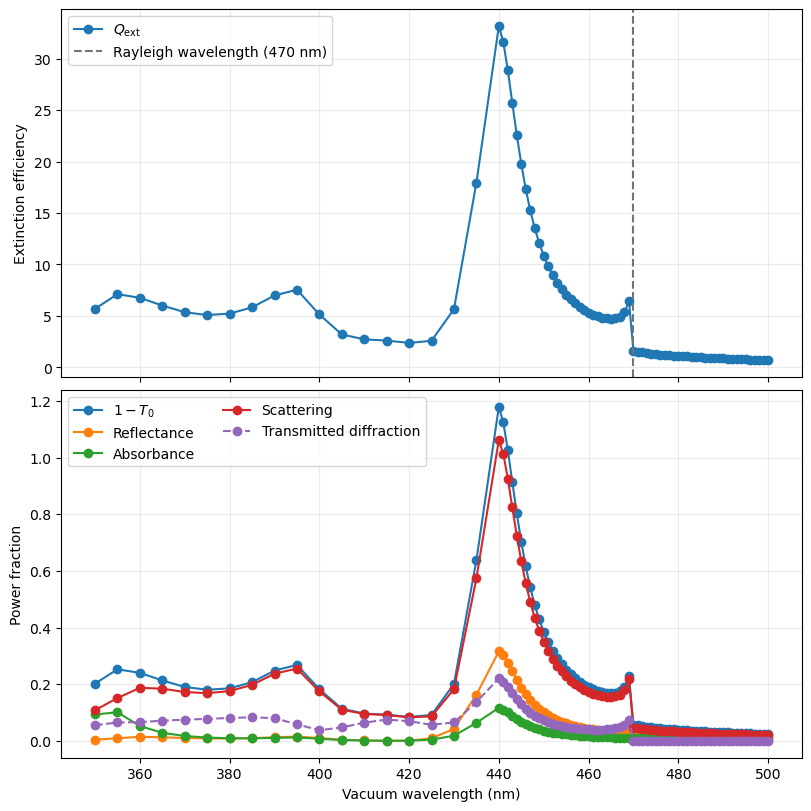

In [15]:
fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), sharex=True, constrained_layout=True
)

axes[0].plot(
    spectrum["wavelength_nm"], spectrum["extinction_efficiency"],
    "o-", label=r"$Q_{\mathrm{ext}}$"
)
axes[0].axvline(
    LATTICE_CONSTANT_NM, color="0.45", linestyle="--",
    label="Rayleigh wavelength (470 nm)"
)
axes[0].set_ylabel("Extinction efficiency")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    spectrum["wavelength_nm"], spectrum["extinctance"],
    "o-", label=r"$1-T_0$"
)
axes[1].plot(
    spectrum["wavelength_nm"], spectrum["R0"], "o-", label="Reflectance"
)
axes[1].plot(
    spectrum["wavelength_nm"], spectrum["absorbance"], "o-", label="Absorbance"
)
axes[1].plot(
    spectrum["wavelength_nm"], spectrum["scattering"], "o-", label="Scattering"
)
axes[1].plot(
    spectrum["wavelength_nm"], spectrum["T_diffraction"],
    "o--", label="Transmitted diffraction"
)
axes[1].set_xlabel("Vacuum wavelength (nm)")
axes[1].set_ylabel("Power fraction")
axes[1].legend(ncol=2)
axes[1].grid(alpha=0.25)
plt.show()

## Validation and convergence

A single FEM discretization is not a converged benchmark. Repeat the full sweep while independently:

1. reducing `PARTICLE_MAX_ELEMENT_NM` from 14 to 10 nm;
2. reducing `AIR_MAX_ELEMENT_NM` from 45 to 32 nm;
3. increasing `FEM_ORDER` from 2 to 3;
4. increasing `AIR_CLEARANCE_TO_MONITOR_NM` from 400 to 500 nm;
5. increasing `AIR_BUFFER_TO_PML_NM` from 100 to 150 nm;
6. increasing `PML_THICKNESS_NM` from 200 to 300 nm;
7. varying `PML_ATTENUATION` between `2.0` and `4.0`.

The extinction peak position and height should stabilize to the required tolerance. Negative absorption, power fractions materially outside $[0,1]$, or sensitivity to physical height, PML thickness, or stretch flag inadequate truncation or discretization.

The anisotropic Maxwell PML is written explicitly in the H(curl) weak form. Quantitative production results should still be accepted only after independently converging the physical-air clearance, monitor-to-PML buffer, PML parameters, mesh, and FEM order.

In [16]:
required_columns = {
    "wavelength_nm", "extinctance", "extinction_cross_section_nm2",
    "extinction_efficiency", "T_modes", "R_modes", "R0",
    "T_diffraction", "T_scattered_modes", "scattering",
    "absorbance", "power_balance_residual",
}
assert required_columns.issubset(spectrum.columns)
assert np.isfinite(spectrum[list(required_columns)].to_numpy()).all()
assert np.all(np.diff(spectrum["wavelength_nm"]) > 0)
assert (spectrum["epsilon_imag"] > 0).all()
assert (spectrum["extinctance"] >= -1e-10).all()
assert (spectrum["extinction_efficiency"] >= -1e-10).all()
print("Basic FEM benchmark checks passed.")

# Optional comparison-ready export:
# output_directory = Path.cwd() / "outputs"
# output_directory.mkdir(parents=True, exist_ok=True)
# spectrum.to_csv(
#     output_directory / "silver_monolayer_fem_spectrum.csv", index=False
# )

Basic FEM benchmark checks passed.
